# Session 1 - NLP Foundations - From Documents to Text

Before we can tokenize or analyze text, we need the **raw text**. Very often that text sits inside a document, most often a **PDF**. In this notebook we get the text *out of* one PDF page, step by step.

What you will do:
1. Read the text of a PDF with **PyMuPDF**.
2. Spot what goes wrong.
3. Fix the problems by hand with a few lines of Python.
4. Try **Docling**, a tool that does most of the cleaning for you.

Our example is one page from the *UZH Annual Report 2023* (in German).

## Setup

The next cell installs the packages on Google Colab. On your own computer it does nothing — set up the environment as described in `README.md`.

In [1]:
%%capture
import sys

# Install dependencies when running in Google Colab.
# On your own computer, set up the environment as described in README.md instead.
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    print("Google Colab environment detected. Installing dependencies...")

    # install
    %pip install pymupdf==2.1 docling==2.150.0 gdown==6.5.1

### Where is the PDF?

The course data is in a `data/` folder. On your own computer it sits next to the `notebooks/` folder. On Colab, we download it first.

In [2]:
from pathlib import Path

if IN_COLAB:
    import gdown
    url = "https://drive.google.com/drive/folders/1HNSjcMQkNUJxHbdAqUWIPrS0E0DCSGcV"
    gdown.download_folder(url=url, output="data")
    DATA_DIR = Path("data")
else:
    DATA_DIR = Path("../data")

PDF_PATH = DATA_DIR / "UZH_Jahresbericht_2023-sample-single.pdf"
print(PDF_PATH, "exists:", PDF_PATH.exists())

../data/UZH_Jahresbericht_2023-sample-single.pdf exists: True


## 1 · Look at the PDF

First, let's *see* the page the way a human sees it. PyMuPDF can draw a page as a picture.

Number of pages: 1


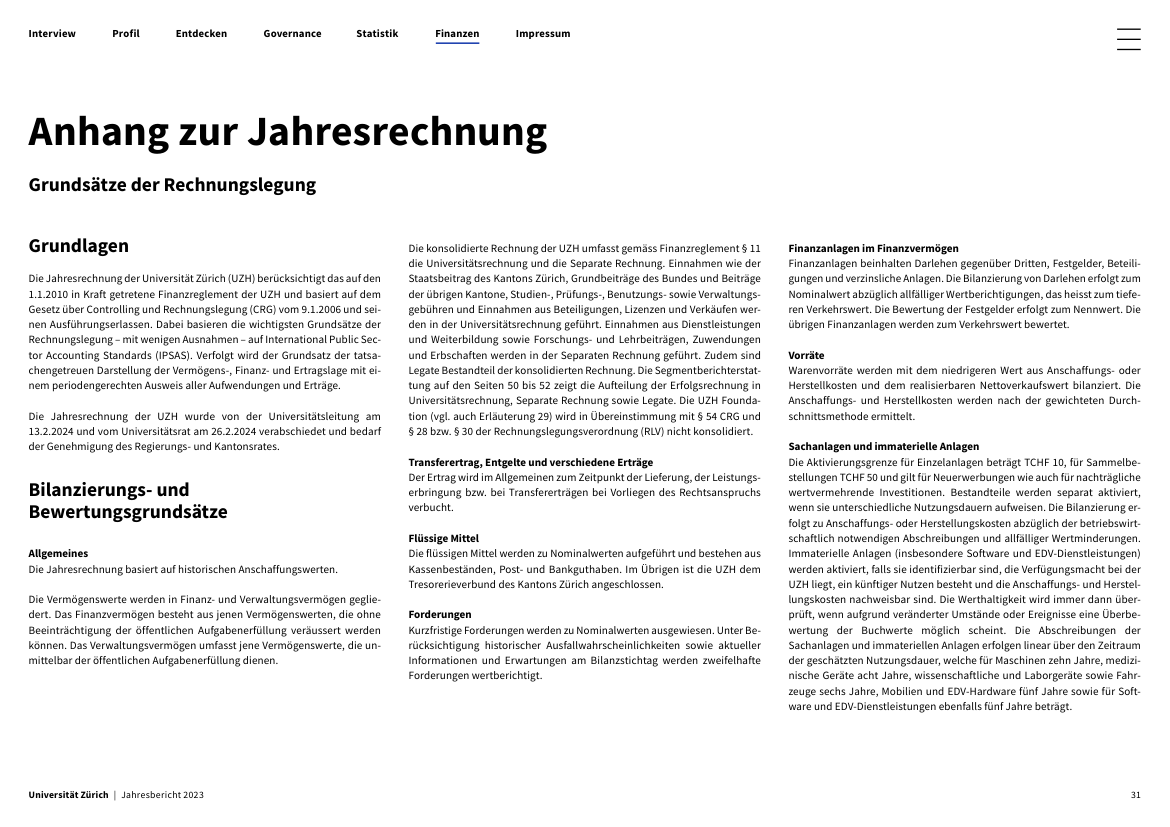

In [3]:
import pymupdf
from IPython.display import Image

pdf = pymupdf.open(PDF_PATH)       # open the file
print("Number of pages:", len(pdf))

page = pdf[0]                      # pages are counted from 0, so this is the first page
picture = page.get_pixmap(dpi=100) # draw the page as an image
Image(picture.tobytes("png"))      # show the image in the notebook

## 2 · Read the text

This PDF is **born-digital**: the text is stored inside the file, so PyMuPDF can read it directly. (A *scanned* PDF is different — we come back to that at the end.)

`page.get_text()` returns all the text of the page as one Python string.

In [4]:
text = page.get_text()

print("Characters:", len(text))
print(text[:700])     # [:700] = only the first 700 characters

Characters: 4889
Interview
Universität Zürich | Jahresbericht 2023
31
Profil
Governance
Statistik
Entdecken
Impressum
Finanzen
Anhang zur Jahresrechnung
Grundsätze der Rechnungslegung
Grundlagen
Die Jahresrechnung der Universität Zürich (UZH) berücksichtigt das auf den 
1.1.2010 in Kraft getretene Finanzreglement der UZH und basiert auf dem 
Gesetz über Controlling und Rechnungslegung (CRG) vom 9.1.2006 und sei-
nen Ausführungserlassen. Dabei basieren die wichtigsten Grundsätze der 
Rechnungslegung – mit wenigen Ausnahmen – auf International Public Sec-
tor Accounting Standards (IPSAS). Verfolgt wird der Grundsatz der tatsa-
chengetreuen Darstellung der Vermögens-, Finanz- und Ertragslage mit ei-
nem periode


### What looks wrong?

Compare the text above with the picture. Three things stand out:

1. **The menu and the footer come first.** Words like `Interview`, `Profil`, `Governance` (the menu at the top of the page) and `Universität Zürich | Jahresbericht 2023` (the footer) are mixed into the start of our text.
2. **Words are split at the end of a line**, for example `tatsa-` and `chengetreuen`. These are one word: `tatsachengetreuen`.
3. **Every line of the page ends with a line break**, even in the middle of a sentence.

Line breaks are invisible when you `print`. Let's make them visible with `repr()`, which shows `\n` for a line break:

In [5]:
start = text.find("tatsa-")             # find() gives the position of the first match
print(repr(text[start - 20 : start + 40]))

'd der Grundsatz der tatsa-\nchengetreuen Darstellung der Verm'


## 3 · Clean up by hand

PyMuPDF can also give us the page in **blocks**. A block is one chunk of text (a heading, a paragraph, a menu) together with its position on the page. Each block is a tuple. We use the first five values:

- `x0, y0` — the top-left corner (`y0` = distance from the top of the page)
- `x1, y1` — the bottom-right corner
- `txt` — the text

In [6]:
blocks = page.get_text("blocks")

for x0, y0, x1, y1, txt, *rest in blocks:     # *rest collects the values we don't need
    print(f"y0 = {y0:5.0f}   {txt[:40]!r}")

y0 =    19   'Interview\n'
y0 =   568   'Universität Zürich | Jahresbericht 2023\n'
y0 =    19   'Profil\nGovernance\nStatistik\nEntdecken\nIm'
y0 =    75   'Anhang zur Jahresrechnung\n'
y0 =   123   'Grundsätze der Rechnungslegung\n'
y0 =   167   'Grundlagen\n'
y0 =   195   'Die Jahresrechnung der Universität Züric'
y0 =   294   'Die Jahresrechnung der UZH wurde von der'
y0 =   343   'Bilanzierungs- und  \nBewertungsgrundsätz'
y0 =   393   'Allgemeines\nDie Jahresrechnung basiert a'
y0 =   426   'Die Vermögenswerte werden in Finanz- und'
y0 =   173   'Die konsolidierte Rechnung der UZH umfas'
y0 =   382   'Flüssige Mittel\nDie flüssigen Mittel wer'
y0 =   437   'Forderungen\nKurzfristige Forderungen wer'
y0 =   173   'Finanzanlagen im Finanzvermögen\nFinanzan'
y0 =   250   'Vorräte\nWarenvorräte werden mit dem nied'
y0 =   316   'Sachanlagen und immaterielle Anlagen\nDie'


The menu has `y0` around 19 and the footer around 568. The real content sits in between. So we can:

1. **keep** only blocks with `y0` between 60 and 540,
2. **glue** words that were split at a line end (remove `-` followed by a line break),
3. **replace** the other line breaks with spaces.

In [7]:
paragraphs = []

for x0, y0, x1, y1, txt, *rest in blocks:
    if 60 < y0 < 540:                       # 1. skip menu (top) and footer (bottom)
        txt = txt.replace("-\n", "")        # 2. glue split words: "tatsa-\nchengetreuen" -> "tatsachengetreuen"
        txt = " ".join(txt.split())         # 3. split() cuts at every space/line break, " ".join() puts them back as single spaces
        paragraphs.append(txt)

clean_text = "\n\n".join(paragraphs)        # one blank line between blocks
print(clean_text[:800])

Anhang zur Jahresrechnung

Grundsätze der Rechnungslegung

Grundlagen

Die Jahresrechnung der Universität Zürich (UZH) berücksichtigt das auf den 1.1.2010 in Kraft getretene Finanzreglement der UZH und basiert auf dem Gesetz über Controlling und Rechnungslegung (CRG) vom 9.1.2006 und seinen Ausführungserlassen. Dabei basieren die wichtigsten Grundsätze der Rechnungslegung – mit wenigen Ausnahmen – auf International Public Sector Accounting Standards (IPSAS). Verfolgt wird der Grundsatz der tatsachengetreuen Darstellung der Vermögens-, Finanz- und Ertragslage mit einem periodengerechten Ausweis aller Aufwendungen und Erträge.

Die Jahresrechnung der UZH wurde von der Universitätsleitung am 13.2.2024 und vom Universitätsrat am 26.2.2024 verabschiedet und bedarf der Genehmigung des Regierungs


Much better. This clean string is what we would give to the tokenizer from the first notebook.

⚠️ **Our rules are guesses.** Step 2 assumes that every `-` at a line end is a split word. A real hyphen at a line end, as in `Bildungs-` / `und Forschung`, would be glued wrongly into `Bildungsund`. On this page all cases are fine. On a new document, always check a few examples.

In [8]:
print("Words before cleaning:", len(text.split()))
print("Words after cleaning: ", len(clean_text.split()))

Words before cleaning: 582
Words after cleaning:  545


## 4 · Docling: let a tool do it

Writing rules by hand works for one page, but every document looks different. **Docling** (IBM, open source) uses machine-learning models to understand the *layout* of a page: which part is a heading, a paragraph, a menu or a footer. It returns **Markdown**, where `##` marks a heading.

Heads-up: the first run downloads some models and can take a minute or two.

(The first line of code makes Docling use the CPU. This avoids an error on Apple Silicon Macs. For one page, the CPU is fast enough.)

In [9]:
import os

# Run Docling on the CPU. On Apple Silicon Macs, Docling would otherwise use the
# Mac GPU ("MPS"), which fails with: "Cannot convert a MPS Tensor to float64".
os.environ["DOCLING_DEVICE"] = "cpu"

from docling.document_converter import DocumentConverter

converter = DocumentConverter()
result = converter.convert(PDF_PATH)

docling_text = result.document.export_to_markdown()
print(docling_text[:900])

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

## Anhang zur Jahresrechnung

## Grundsätze der Rechnungslegung

## Grundlagen

Die Jahresrechnung der Universität Zürich (UZH) berücksichtigt das auf den 1.1.2010 in Kraft getretene Finanzreglement der UZH und basiert auf dem Gesetz über Controlling und Rechnungslegung (CRG) vom 9.1.2006 und seinen Ausführungserlassen. Dabei basieren die wichtigsten Grundsätze der Rechnungslegung - mit wenigen Ausnahmen - auf International Public Sector Accounting Standards (IPSAS). Verfolgt wird der Grundsatz der tatsachengetreuen Darstellung der Vermögens-, Finanz- und Ertragslage mit einem periodengerechten Ausweis aller Aufwendungen und Erträge.

Die Jahresrechnung der UZH wurde von der Universitätsleitung am 13.2.2024 und vom Universitätsrat am 26.2.2024 verabschiedet und bedarf der Genehmigung des Regierungs- und Kantonsrates.

## Bilanzierungs- und Bewertungsgrundsätze

## Allgemeines

Die Jahres


Compare with our hand-made result:

| | PyMuPDF + our rules | Docling |
|---|---|---|
| Menu and footer removed | yes (by position) | yes (automatically) |
| Split words glued | yes (our rule) | yes |
| Headings marked | no | yes (`##`) |
| Speed and size | fast, small | slower, downloads models |

There is no best tool. For simple, born-digital PDFs, PyMuPDF is often enough. For complex layouts, tools like Docling save a lot of work.

## 5 · What about scanned PDFs?

A **scanned** document is only a *picture* of text. There is no text inside the file, so a text extractor has nothing to read. Let's try it on a scanned dictionary page (an image file):

In [10]:
scan = pymupdf.open(DATA_DIR / "Franz_Etymolog_Woerterbuch_0033.png")   # PyMuPDF can open images, too
scan_text = scan[0].get_text()

print("Extracted text:", repr(scan_text))    # '' means: empty

Extracted text: ''


The result is an empty string. A quick rule: **if `get_text()` returns nothing, the page is probably a scan** and needs **OCR** (optical character recognition) or a vision-language model. We do exactly this in **Session 4**.